### Fashion-MNIST PCA 降维

流程：读取数据 → 分层抽样 7000 个样本（`SEED = 42`）→ 在另一份调参样本上扫描参数并选定 → PCA 降维 → 保存结果。

`fashion-PCA.ipynb` 和 `fashion-UMAP.ipynb` 的数据读取、抽样和评估代码完全相同，两边降维用的是同一批样本，选参数用的也是同一批调参样本和同一套指标。

数据来源：Zalando Research 官方 idx 文件，首次运行会下载到 `dataset/`。

In [1]:
import gzip
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.metrics import pairwise_distances, adjusted_rand_score, normalized_mutual_info_score
from sklearn.manifold import trustworthiness

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

SEED = 42
SAMPLE_RATIO = 0.1
TUNE_SEED = 0       # 调参样本的随机种子，与 SEED 不同

#### 1. 读取数据

训练集和测试集合并成 70000 个样本，每张图展平成 784 维，像素缩放到 [0, 1]。

In [2]:
DATA_DIR = Path('dataset')
DATA_DIR.mkdir(exist_ok=True)

BASE_URL = 'http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/'
FILES = ['train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz',
         't10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz']
for fname in FILES:
    if not (DATA_DIR / fname).exists():
        print(f'下载 {fname} ...')
        urllib.request.urlretrieve(BASE_URL + fname, DATA_DIR / fname)

def load_images(path):
    # idx3 头部 16 字节：magic, 数量, 行数, 列数
    with gzip.open(path, 'rb') as f:
        return np.frombuffer(f.read(), dtype=np.uint8, offset=16).reshape(-1, 784)

def load_labels(path):
    # idx1 头部 8 字节：magic, 数量
    with gzip.open(path, 'rb') as f:
        return np.frombuffer(f.read(), dtype=np.uint8, offset=8)

X_full = np.concatenate([load_images(DATA_DIR / FILES[0]),
                         load_images(DATA_DIR / FILES[2])]).astype(np.float32) / 255.0
y_full = np.concatenate([load_labels(DATA_DIR / FILES[1]),
                         load_labels(DATA_DIR / FILES[3])])

CLASS_NAMES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print('X_full:', X_full.shape, ' y_full:', y_full.shape)

X_full: (70000, 784)  y_full: (70000,)


#### 2. 分层抽样 1/10

在 70000 个样本上整体分层抽样 10%，每类 700 张，共 7000 张。`random_state` 固定，每次抽到的样本相同。

In [3]:
sample_idx, _ = train_test_split(
    np.arange(len(y_full)),
    train_size=SAMPLE_RATIO,
    stratify=y_full,
    random_state=SEED,
)
sample_idx = np.sort(sample_idx)

X = X_full[sample_idx]
y = y_full[sample_idx]

print('X:', X.shape, ' y:', y.shape)
print('前 10 个抽中的索引:', sample_idx[:10])
print('每类数量:', np.bincount(y).tolist())

X: (7000, 784)  y: (7000,)
前 10 个抽中的索引: [13 21 22 25 40 50 60 68 86 93]
每类数量: [700, 700, 700, 700, 700, 700, 700, 700, 700, 700]


#### 3. 选择降维参数

参数不能在 SEED=42 这批评估样本上参考真实标签来挑，否则后面在这批样本上算 ARI、NMI 时等于提前看过答案。所以从剩下的 63000 个样本里再分层抽一份 7000 个样本（`TUNE_SEED = 0`，与评估样本不重叠），只在这份调参样本上扫描参数。

In [4]:
rest_idx = np.setdiff1d(np.arange(len(y_full)), sample_idx)
tune_idx, _ = train_test_split(
    rest_idx,
    train_size=len(sample_idx),
    stratify=y_full[rest_idx],
    random_state=TUNE_SEED,
)
tune_idx = np.sort(tune_idx)
assert len(np.intersect1d(tune_idx, sample_idx)) == 0

X_tune = X_full[tune_idx]
y_tune = y_full[tune_idx]

print('X_tune:', X_tune.shape, ' 与评估样本重叠:', len(np.intersect1d(tune_idx, sample_idx)))
print('每类数量:', np.bincount(y_tune).tolist())

X_tune: (7000, 784)  与评估样本重叠: 0
每类数量: [700, 700, 700, 700, 700, 700, 700, 700, 700, 700]


##### 3.1 评估指标与选择规则

每个参数配置在调参样本上降维后计算以下指标：

| 指标 | 计算方式 | 反映什么 |
|---|---|---|
| `ari`、`nmi` | 降维结果上跑 KMeans（k=10，`n_init=10`），与真实类别比较 | 聚类和真实类别的吻合程度 |
| `score` | `(ari + nmi) / 2` | **选参数的依据** |
| `knn_acc` | 降维结果上 10 近邻分类器的 5 折交叉验证准确率 | 类别信息保留了多少，不依赖聚类算法 |
| `trust` | trustworthiness（k=10）：降维后的近邻在原空间中是否也是近邻，1 为完全保留 | 局部结构保留了多少，不用标签 |

选择规则：`score` 与最高值相差不超过 `TOL = 0.01` 的配置算作并列最好，其中取维数最小的，维数相同再取 `score` 最高的。KMeans 结果受初始化影响，0.01 以内的差距说明不了好坏，这时维数少的更简单、聚类也更快。`knn_acc` 和 `trust` 不参与选择，用来确认选中的配置在其他方面没有明显变差。

sklearn 的 `trustworthiness` 每次都重算 7000×7000 的距离矩阵和排名，内存占用约 1 GB。这里先把原空间的近邻排名算一次，之后每个配置只算降维空间的近邻，公式与 sklearn 相同，下面在 2000 个样本上和 sklearn 的结果核对。

In [5]:
TOL = 0.01
K_TRUST = 10

def original_ranks(X, chunk=1000):
    # ranks[i, j]：原空间中 j 是 i 的第几近邻（自身为 0）
    n = len(X)
    ranks = np.empty((n, n), dtype=np.int32)
    for s in range(0, n, chunk):
        d = pairwise_distances(X[s:s + chunk], X)
        d[np.arange(len(d)), np.arange(s, s + len(d))] = -1   # 自身排在最前
        order = np.argsort(d, axis=1)
        np.put_along_axis(ranks[s:s + chunk], order, np.arange(n, dtype=np.int32)[None, :], axis=1)
    return ranks

def trust_score(ranks, E, k=K_TRUST):
    # 与 sklearn.manifold.trustworthiness 的公式相同
    n = len(E)
    nbr = NearestNeighbors(n_neighbors=k).fit(E).kneighbors(return_distance=False)
    r = np.take_along_axis(ranks, nbr, axis=1) - k
    return 1 - 2.0 / (n * k * (2 * n - 3 * k - 1)) * r[r > 0].sum()

def evaluate(E, y, ranks):
    pred = KMeans(n_clusters=10, n_init=10, random_state=SEED).fit_predict(E)
    ari = adjusted_rand_score(y, pred)
    nmi = normalized_mutual_info_score(y, pred)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    knn_acc = cross_val_score(KNeighborsClassifier(n_neighbors=10), E, y, cv=cv).mean()
    return dict(score=(ari + nmi) / 2, ari=ari, nmi=nmi, knn_acc=knn_acc, trust=trust_score(ranks, E))

def pick(df, dim_col='n_components'):
    # score 在最高值 TOL 以内的配置里，取维数最小的，再取 score 最高的
    tied = df[df['score'] >= df['score'].max() - TOL]
    return tied.sort_values([dim_col, 'score'], ascending=[True, False]).iloc[0], tied

METRIC_COLS = ['score', 'ari', 'nmi', 'knn_acc', 'trust']
METRIC_FMT = {c: '{:.3f}' for c in METRIC_COLS}

ranks_tune = original_ranks(X_tune)

# 和 sklearn 核对（取 2000 个样本、每隔 8 个像素取一列当作"降维结果"）
X_chk, E_chk = X_tune[:2000], X_tune[:2000, ::8]
print(f'trust_score: {trust_score(original_ranks(X_chk), E_chk):.6f}')
print(f'sklearn    : {trustworthiness(X_chk, E_chk, n_neighbors=K_TRUST):.6f}')

trust_score: 0.989180


sklearn    : 0.989180


##### 3.2 扫描 PCA 参数

PCA 要定的参数有两个：

- `n_components`：保留几个主成分。维数少丢信息，维数多会把噪声也带进来，KMeans 的距离计算也更受干扰。
- `whiten`：是否把每个主成分缩放到方差为 1。不白化时前几个主成分方差大，在欧氏距离里占主导；白化后各成分权重相同，后面方差很小、以噪声为主的成分会被放大。

`evr`（累计解释方差）和 `recon_mse`（重建误差）只和维数有关，与是否白化无关，列出来作参考。表里最后一行是不降维（784 维原始像素）的结果，作为对照。

In [6]:
PCA_GRID = dict(n_components=[2, 5, 10, 20, 30, 50, 80, 100, 150], whiten=[False, True])

rows = []
for n in PCA_GRID['n_components']:
    for w in PCA_GRID['whiten']:
        p = PCA(n_components=n, whiten=w, random_state=SEED).fit(X_tune)
        E = p.transform(X_tune)
        recon_mse = np.mean((p.inverse_transform(E) - X_tune) ** 2)
        rows.append(dict(n_components=n, whiten=w, evr=p.explained_variance_ratio_.sum(),
                         recon_mse=recon_mse, **evaluate(E, y_tune, ranks_tune)))
pca_sweep = pd.DataFrame(rows)

raw_row = pd.DataFrame([dict(n_components=X_tune.shape[1], whiten='不降维', evr=1.0,
                             recon_mse=0.0, **evaluate(X_tune, y_tune, ranks_tune))])

SWEEP_FILE = Path('result') / 'pca-param-sweep.csv'
SWEEP_FILE.parent.mkdir(exist_ok=True)
pd.concat([pca_sweep, raw_row]).to_csv(SWEEP_FILE, index=False, encoding='utf-8-sig')  # utf-8-sig 让 Excel 正确显示中文
print('扫描结果已保存:', SWEEP_FILE)

扫描结果已保存: result\pca-param-sweep.csv


3.3 扫描结果

表 1 是全部配置，按维数排列，颜色越深数值越大。

In [7]:
(pd.concat([pca_sweep, raw_row], ignore_index=True)
   .style.format({**METRIC_FMT, 'evr': '{:.1%}', 'recon_mse': '{:.4f}'})
   .background_gradient(subset=METRIC_COLS, cmap='Greens')
   .set_caption('表 1  PCA 参数扫描（调参样本）'))

,n_components,whiten,evr,recon_mse,score,ari,nmi,knn_acc,trust
0,2,False,47.0%,0.0462,0.355,0.287,0.423,0.523,0.912
1,2,True,47.0%,0.0462,0.346,0.269,0.424,0.525,0.912
2,5,False,61.6%,0.0335,0.429,0.355,0.502,0.724,0.983
3,5,True,61.6%,0.0335,0.399,0.312,0.487,0.725,0.981
4,10,False,72.0%,0.0244,0.419,0.337,0.500,0.785,0.993
5,10,True,72.0%,0.0244,0.429,0.340,0.518,0.787,0.992
6,20,False,78.5%,0.0188,0.420,0.339,0.502,0.817,0.997
7,20,True,78.5%,0.0188,0.428,0.341,0.516,0.825,0.993
8,30,False,82.1%,0.0156,0.414,0.328,0.500,0.821,0.998
9,30,True,82.1%,0.0156,0.432,0.341,0.523,0.832,0.992


表 2 把 `score` 按维数和是否白化排成两列，方便直接比较白化的影响。

In [8]:
(pca_sweep.pivot(index='n_components', columns='whiten', values='score')
   .rename(columns={False: '不白化', True: '白化'})
   .style.format('{:.3f}').background_gradient(cmap='Greens', axis=None)
   .set_caption('表 2  score = (ARI + NMI) / 2'))

whiten,不白化,白化
n_components,,
2,0.355,0.346
5,0.429,0.399
10,0.419,0.429
20,0.420,0.428
30,0.414,0.432
50,0.449,0.406
80,0.438,0.391
100,0.439,0.393
150,0.414,0.329


##### 3.4 按规则选定参数

表 3 列出 `score` 与最高值相差不超过 `TOL` 的配置，按规则取第一行。

In [9]:
best_pca, tied_pca = pick(pca_sweep)
PCA_N_COMPONENTS = int(best_pca['n_components'])
PCA_WHITEN = bool(best_pca['whiten'])

display(tied_pca.sort_values(['n_components', 'score'], ascending=[True, False])
        .style.format({**METRIC_FMT, 'evr': '{:.1%}', 'recon_mse': '{:.4f}'})
        .set_caption(f'表 3  score ≥ {pca_sweep["score"].max():.3f} - {TOL} 的配置'))
print(f'选定: n_components={PCA_N_COMPONENTS}, whiten={PCA_WHITEN}')
print(f'  score={best_pca["score"]:.3f}（最高 {pca_sweep["score"].max():.3f}，不降维 {raw_row["score"].iloc[0]:.3f}）')

,n_components,whiten,evr,recon_mse,score,ari,nmi,knn_acc,trust
10,50,False,86.3%,0.0119,0.449,0.377,0.521,0.824,0.999
14,100,False,91.3%,0.0076,0.439,0.370,0.509,0.824,1.000


选定: n_components=50, whiten=False
  score=0.449（最高 0.449，不降维 0.421）


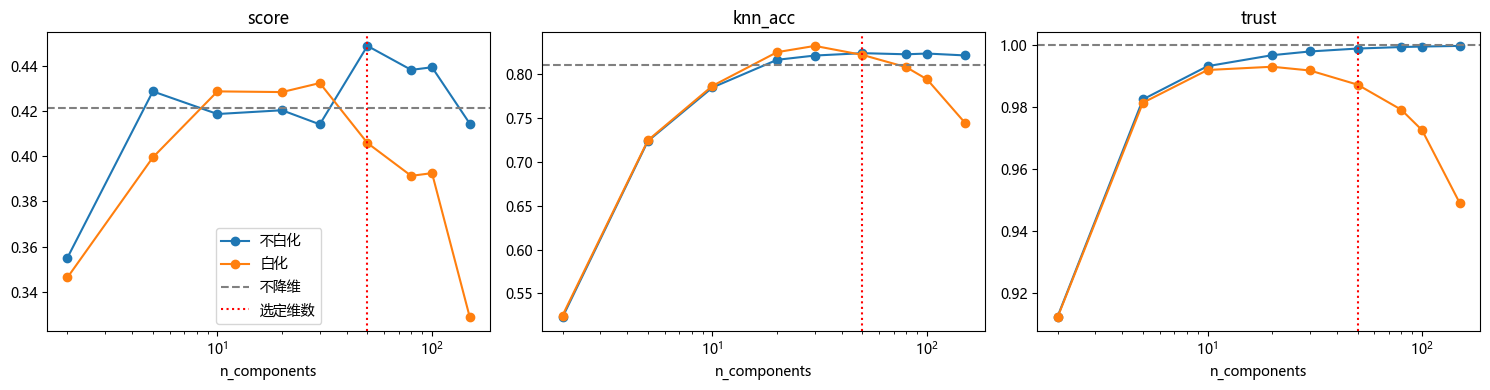

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['score', 'knn_acc', 'trust']):
    for w, label in [(False, '不白化'), (True, '白化')]:
        d = pca_sweep[pca_sweep['whiten'] == w]
        ax.plot(d['n_components'], d[col], marker='o', label=label)
    ax.axhline(raw_row[col].iloc[0], color='gray', ls='--', label='不降维')
    ax.axvline(PCA_N_COMPONENTS, color='red', ls=':', label='选定维数')
    ax.set_xscale('log')
    ax.set_xlabel('n_components')
    ax.set_title(col)
axes[0].legend()
plt.tight_layout()
plt.show()

#### 4. PCA 降维

用第 3 节选定的 `PCA_N_COMPONENTS` 和 `PCA_WHITEN`，在评估样本上拟合 PCA，结果用于聚类。前 2 个主成分用于画图。

In [11]:
pca = PCA(n_components=PCA_N_COMPONENTS, whiten=PCA_WHITEN, random_state=SEED)
X_red = pca.fit_transform(X)
X_red_2d = X_red[:, :2]

evr = pca.explained_variance_ratio_
print('降维后:', X_red.shape, ' whiten:', PCA_WHITEN)
print(f'前 {PCA_N_COMPONENTS} 个主成分累计解释方差: {evr.sum():.1%}')

降维后: (7000, 50)  whiten: False
前 50 个主成分累计解释方差: 86.3%


#### 5. 保存结果

结果保存在变量 `fashion_pca_redu_result`（字典）中，同时写入 `result/fashion-pca-redu-result.npz`。后续聚类直接读文件，不用重跑降维：

```python
r = np.load('result/fashion-pca-redu-result.npz')
X, y = r['embedding'], r['labels']
```

| 键 | 内容 |
|---|---|
| `embedding` | (7000, PCA_N_COMPONENTS) 降维结果，聚类用 |
| `embedding_2d` | (7000, 2)，画图用 |
| `labels` | 真实类别（整数），只用于 ARI、NMI 等外部指标，聚类时不能用 |
| `class_names` | 类别名，下标对应 `labels` |
| `sample_idx` | 在 70000 个原始样本中的索引，PCA 与 UMAP 两份结果应完全相同 |
| `explained_variance_ratio` | 各主成分的解释方差比例 |
| `n_components`、`whiten` | 第 3 节选定的 PCA 参数 |
| `seed` | 随机种子 |
| `tune_idx` | 调参样本在 70000 个原始样本中的索引，PCA 与 UMAP 两份结果应完全相同 |

In [12]:
fashion_pca_redu_result = {
    'embedding': X_red.astype(np.float32),
    'embedding_2d': X_red_2d.astype(np.float32),
    'labels': y,
    'class_names': np.array(CLASS_NAMES),
    'sample_idx': sample_idx,
    'explained_variance_ratio': pca.explained_variance_ratio_,
    'n_components': PCA_N_COMPONENTS,
    'whiten': PCA_WHITEN,
    'seed': SEED,
    'tune_idx': tune_idx,
}

RESULT_FILE = Path('result') / 'fashion-pca-redu-result.npz'
RESULT_FILE.parent.mkdir(exist_ok=True)
np.savez(RESULT_FILE, **fashion_pca_redu_result)

# 读回来逐项核对
with np.load(RESULT_FILE) as saved:
    assert all(np.array_equal(saved[k], v) for k, v in fashion_pca_redu_result.items())
print('已保存并校验:', RESULT_FILE)
for k, v in fashion_pca_redu_result.items():
    print(f'  {k}: shape={np.shape(v)}, dtype={np.asarray(v).dtype}')

已保存并校验: result\fashion-pca-redu-result.npz
  embedding: shape=(7000, 50), dtype=float32
  embedding_2d: shape=(7000, 2), dtype=float32
  labels: shape=(7000,), dtype=uint8
  class_names: shape=(10,), dtype=<U11
  sample_idx: shape=(7000,), dtype=int64
  explained_variance_ratio: shape=(50,), dtype=float32
  n_components: shape=(), dtype=int64
  whiten: shape=(), dtype=bool
  seed: shape=(), dtype=int64
  tune_idx: shape=(7000,), dtype=int64


#### 6. 可视化检查

二维结果按真实类别着色，只用来确认降维结果正常。

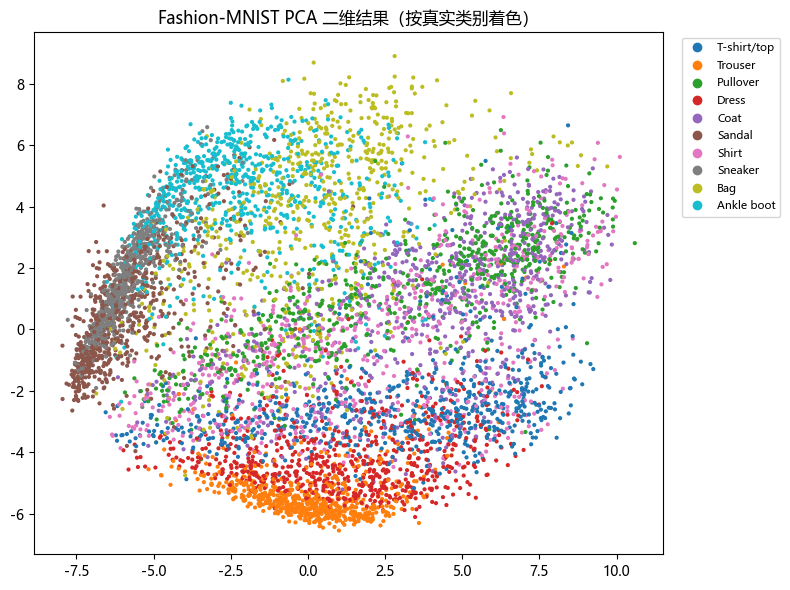

In [13]:
emb2 = fashion_pca_redu_result['embedding_2d']
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(emb2[:, 0], emb2[:, 1], c=y, cmap='tab10', s=4)
ax.legend(sc.legend_elements()[0], CLASS_NAMES, fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
ax.set_title('Fashion-MNIST PCA 二维结果（按真实类别着色）')
plt.tight_layout()
plt.show()